In [ ]:
%pip install -q faster-whisper sentence-transformers librosa soundfile
%pip install -q "av>=11,<19"

Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × pip subprocess to install build dependencies did not run successfully.
  │ exit code: 1
  ╰─> [14 lines of output]
        Using cached setuptools-82.0.1-py3-none-any.whl.metadata (6.5 kB)
        Using cached cython-3.3.0-cp39-cp39-win_amd64.whl.metadata (28 kB)
        Using cached cymem-2.0.13-cp39-cp39-win_amd64.whl.metadata (9.9 kB)
        Using cached preshed-3.0.13-cp39-cp39-win_amd64.whl.metadata (5.4 kB)
        Using cached murmurhash-1.0.15-cp39-cp39-win_amd64.whl.metadata (2.3 kB)
      ERROR: Ignored the following yanked versions: 6.10.4.dev0, 7.4.4, 8.3.5
      ERROR: Ignored the following versions that require a different python version: 8.3.10 Requires-Python <3.15,>=3.10; 8.3.11 Requires-Python <3.15,>=3.10; 8.3.12 Requires-Python <3.15,>=3.10; 8.3.13 Requires-Python <3.15,>=3.10; 83.0.0 Requires-Python >=3.10; 84.0.0 Requires-Python >=3.10
      ERROR: Could not find a version that satisfies the requirement thinc<8.4.0,>=8

Note: you may need to restart the kernel to use updated packages.


## 1. Environment

This notebook uses `small.en` on CUDA with `int8_float16` when a GPU is available.

For reproducibility, the final notebook does **not** automatically run `pip install`; Kaggle network/package availability can vary. Run the notebook only after the required packages are available in the environment.


In [1]:
from pathlib import Path
import json
import hashlib
import re
import warnings
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import librosa
import soundfile as sf

from scipy import sparse
from scipy.stats import pearsonr

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error

from faster_whisper import WhisperModel
from sentence_transformers import SentenceTransformer

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

required_modules = {
    "faster_whisper": "faster-whisper",
    "sentence_transformers": "sentence-transformers",
    "librosa": "librosa",
    "soundfile": "soundfile",
    "torch": "torch",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
}

print("Package availability:")
missing = []

for module, package in required_modules.items():
    ok = importlib.util.find_spec(module) is not None
    print(f"{package:22s}: {'OK' if ok else 'MISSING'}")
    if not ok:
        missing.append(package)

if missing:
    raise ImportError(
        "Missing packages: "
        + ", ".join(missing)
        + ". Install/enable them in the Kaggle environment before running."
    )

print("\nEnvironment ready.")
print("CUDA available:", torch.cuda.is_available())

Package availability:
faster-whisper        : OK
sentence-transformers : OK
librosa               : OK
soundfile             : OK
torch                 : OK
scikit-learn          : OK
scipy                 : OK

Environment ready.
CUDA available: True


## 2. Dataset discovery and CSV audit

In [ ]:
DATA_DIR = Path("data").resolve()

TRAIN_CSV = DATA_DIR / "train.csv"
TEST_CSV = DATA_DIR / "test.csv"

TRAIN_AUDIO_DIR = DATA_DIR / "train"
TEST_AUDIO_DIR = DATA_DIR / "test"

if not TRAIN_CSV.exists() or not TEST_CSV.exists():
    raise FileNotFoundError(f"Expected train.csv and test.csv under {DATA_DIR}")

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("DATA_DIR:", DATA_DIR)
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nTrain columns:", train_df.columns.tolist())
print("Test columns :", test_df.columns.tolist())

ID_CANDIDATES = ["filename", "file_name", "audio", "id", "ID"]
TARGET_CANDIDATES = ["label", "score", "target", "grammar_score"]

def first_existing(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

ID_COL = first_existing(train_df, ID_CANDIDATES)
TARGET_COL = first_existing(train_df, TARGET_CANDIDATES)

if ID_COL is None or TARGET_COL is None:
    raise ValueError(
        f"Could not infer train columns. ID_COL={ID_COL}, TARGET_COL={TARGET_COL}"
    )

if ID_COL not in test_df.columns:
    raise ValueError(f"test.csv is missing the ID column: {ID_COL}")

SUB_ID_COL = ID_COL
SUB_PRED_COL = TARGET_COL

train_df[ID_COL] = train_df[ID_COL].astype(str)
test_df[ID_COL] = test_df[ID_COL].astype(str)

y = train_df[TARGET_COL].astype(float).to_numpy()

print("\nResolved columns:")
print("ID_COL       :", ID_COL)
print("TARGET_COL   :", TARGET_COL)
print("SUB_ID_COL   :", SUB_ID_COL)
print("SUB_PRED_COL :", SUB_PRED_COL)

print("\nLabel distribution:")
display(train_df[TARGET_COL].value_counts(dropna=False).sort_index().rename("count").to_frame())

print("\nDuplicate CSV IDs:")
print("train:", int(train_df[ID_COL].duplicated().sum()))
print("test :", int(test_df[ID_COL].duplicated().sum()))

train_ids = set(train_df[ID_COL])
test_ids = set(test_df[ID_COL])

print("\nTrain/Test ID overlap:", len(train_ids & test_ids))

zero_count = int((y == 0).sum())
print("Zero-labelled training rows:", zero_count)
print("Non-zero training rows:", len(y) - zero_count)


DATA_DIR: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
Train shape: (769, 2)
Test shape: (216, 2)

Train columns: ['filename', 'label']
Test columns : ['filename', 'label']

Resolved columns:
ID_COL       : filename
TARGET_COL   : label
SUB_ID_COL   : filename
SUB_PRED_COL : label

Label distribution:


,count
label,
0.0,37
1.0,1
1.5,3
2.0,102
2.5,79
3.0,174
3.5,64
4.0,124
4.5,52



Duplicate CSV IDs:
train: 0
test : 0

Train/Test ID overlap: 212
Zero-labelled training rows: 37
Non-zero training rows: 732


## 3. Audio indexing + exact duplicate check

Two different filenames can still contain identical audio. We therefore compute MD5 hashes without loading whole files into memory.

The hash is also used as a grouping variable during cross-validation so identical training recordings cannot cross validation folds.


In [3]:
all_wavs = list(DATA_DIR.rglob("*.wav"))

if not all_wavs:
    raise FileNotFoundError(
        "No .wav files found below DATA_DIR."
    )

audio_by_name = {}

for p in all_wavs:
    audio_by_name.setdefault(
        p.name,
        []
    ).append(p)

print(
    "Total WAV files discovered:",
    len(all_wavs)
)


def resolve_audio(
    filename,
    preferred_dir=None
):
    filename = str(filename)

    if preferred_dir is not None:
        direct = preferred_dir / filename
        if direct.exists():
            return direct

    candidates = audio_by_name.get(
        filename,
        []
    )

    if preferred_dir is not None:
        candidates = [
            p
            for p in candidates
            if preferred_dir in p.parents
        ]

    if len(candidates) == 1:
        return candidates[0]

    if len(candidates) > 1:
        split_hits = [
            p
            for p in candidates
            if p.parent.name.lower() in {"train", "test"}
        ]
        if len(split_hits) == 1:
            return split_hits[0]

    return None


train_df["audio_path"] = [
    resolve_audio(f, TRAIN_AUDIO_DIR)
    for f in train_df[ID_COL]
]

test_df["audio_path"] = [
    resolve_audio(f, TEST_AUDIO_DIR)
    for f in test_df[ID_COL]
]

print(
    "Resolved train audio:",
    int(train_df["audio_path"].notna().sum()),
    "/",
    len(train_df)
)

print(
    "Resolved test audio:",
    int(test_df["audio_path"].notna().sum()),
    "/",
    len(test_df)
)

if train_df["audio_path"].isna().any():
    print(
        train_df.loc[
            train_df["audio_path"].isna(),
            ID_COL
        ].head(20).tolist()
    )
    raise FileNotFoundError(
        "Some training audio files could not be resolved."
    )

if test_df["audio_path"].isna().any():
    print(
        test_df.loc[
            test_df["audio_path"].isna(),
            ID_COL
        ].head(20).tolist()
    )
    raise FileNotFoundError(
        "Some test audio files could not be resolved."
    )


def md5_file(
    path,
    chunk_size=1024 * 1024
):
    """Compute an MD5 hash without loading the whole file."""
    h = hashlib.md5()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)

    return h.hexdigest()


hash_rows = []

for split_name, df in [
    ("train", train_df),
    ("test", test_df)
]:
    for filename, path in tqdm(
        zip(
            df[ID_COL],
            df["audio_path"]
        ),
        total=len(df),
        desc=f"Hashing {split_name}"
    ):
        hash_rows.append(
            {
                "filename": str(filename),
                "split": split_name,
                "audio_hash": md5_file(Path(path))
            }
        )

audio_hash_df = pd.DataFrame(
    hash_rows
)


# Split-specific lookup maps.
train_hash_map = (
    audio_hash_df[
        audio_hash_df["split"] == "train"
    ]
    .drop_duplicates("filename")
    .set_index("filename")["audio_hash"]
    .to_dict()
)

test_hash_map = (
    audio_hash_df[
        audio_hash_df["split"] == "test"
    ]
    .drop_duplicates("filename")
    .set_index("filename")["audio_hash"]
    .to_dict()
)

train_df["audio_hash"] = (
    train_df[ID_COL].map(train_hash_map)
)

test_df["audio_hash"] = (
    test_df[ID_COL].map(test_hash_map)
)

assert train_df["audio_hash"].notna().all()
assert test_df["audio_hash"].notna().all()


# Duplicate audio inside train.
train_dup_groups = (
    audio_hash_df[
        audio_hash_df["split"] == "train"
    ]
    .groupby("audio_hash")
    .size()
)

train_dup_groups = train_dup_groups[
    train_dup_groups > 1
]

print(
    "\nExact duplicate audio groups inside TRAIN:",
    len(train_dup_groups)
)


# Duplicate audio inside test.
test_dup_groups = (
    audio_hash_df[
        audio_hash_df["split"] == "test"
    ]
    .groupby("audio_hash")
    .size()
)

test_dup_groups = test_dup_groups[
    test_dup_groups > 1
]

print(
    "Exact duplicate audio groups inside TEST:",
    len(test_dup_groups)
)


# Exact train/test content duplication.
train_hashes = set(
    train_hash_map.values()
)

test_hashes = set(
    test_hash_map.values()
)

cross_split_hashes = (
    train_hashes &
    test_hashes
)

print(
    "Exact duplicate audio across TRAIN/TEST:",
    len(cross_split_hashes)
)

if cross_split_hashes:
    display(
        audio_hash_df[
            audio_hash_df["audio_hash"].isin(
                cross_split_hashes
            )
        ].sort_values(
            "audio_hash"
        )
    )


# Explicit common-filename content check using cached hashes.
common_names = sorted(
    set(train_df[ID_COL]) &
    set(test_df[ID_COL])
)

same_content_common_names = [
    f
    for f in common_names
    if train_hash_map[f] == test_hash_map[f]
]

print(
    f"Byte-identical audio among common train/test filenames: "
    f"{len(same_content_common_names)} / {len(common_names)}"
)

if same_content_common_names:
    print(
        "WARNING: identical audio appears in both train and test. "
        "Do not claim this is a clean generalization benchmark."
    )


Total WAV files discovered: 985
Resolved train audio: 769 / 769
Resolved test audio: 216 / 216


Hashing train:   0%|          | 0/769 [00:00<?, ?it/s]

Hashing test:   0%|          | 0/216 [00:00<?, ?it/s]


Exact duplicate audio groups inside TRAIN: 0
Exact duplicate audio groups inside TEST: 0
Exact duplicate audio across TRAIN/TEST: 0
Byte-identical audio among common train/test filenames: 0 / 212


## 4. Evaluation target

In [4]:
target_df = test_df[[ID_COL, "audio_path"]].copy()
TARGET_SOURCE = "test.csv"

assert target_df[ID_COL].is_unique, "test.csv contains duplicate evaluation IDs."
assert target_df["audio_path"].notna().all(), "Some test.csv rows do not have corresponding audio files."

print("Evaluation target source:", TARGET_SOURCE)
print("Evaluation rows:", len(target_df))
print("Test columns:", test_df.columns.tolist())


Evaluation target source: test.csv
Evaluation rows: 216
Test columns: ['filename', 'label', 'audio_path', 'audio_hash']


## 5. Runtime configuration

`small.en` is used instead of `base.en` to improve transcript quality while remaining practical on a Kaggle GPU.

Cache names include the Whisper configuration so a model upgrade cannot accidentally reuse transcripts or embeddings generated with an older model.


In [ ]:
OUTPUT_DIR = Path("output").resolve()
ARTIFACT_DIR = OUTPUT_DIR / "artifacts"
CACHE_DIR = ARTIFACT_DIR / "cache"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

WHISPER_MODEL_NAME = "small.en"
WHISPER_BEAM_SIZE = 3
CACHE_VERSION = "v2"

WHISPER_COMPUTE_TYPE = "int8_float16" if DEVICE == "cuda" else "int8"

print("Device:", DEVICE)
print("Whisper model:", WHISPER_MODEL_NAME)
print("Whisper compute type:", WHISPER_COMPUTE_TYPE)

print("Whisper beam size:", WHISPER_BEAM_SIZE)

Device: cuda
Whisper model: small.en
Whisper compute type: int8_float16
Whisper beam size: 3


## 6. Faster-Whisper transcription

The transcript and timing metadata are cached. Word timestamps are retained for speech-rate and pause features.

In [9]:

asr_model = WhisperModel(
    WHISPER_MODEL_NAME,
    device=DEVICE,
    compute_type=WHISPER_COMPUTE_TYPE,
)

ASR_CACHE_TAG = (
    f"{WHISPER_MODEL_NAME}_beam{WHISPER_BEAM_SIZE}_{CACHE_VERSION}"
    .replace(".", "_")
)

def transcribe_one(path):
    segments, info = asr_model.transcribe(
        str(path),
        language="en",
        beam_size=WHISPER_BEAM_SIZE,
        best_of=1,
        temperature=0.0,
        word_timestamps=True,
        condition_on_previous_text=False,
        vad_filter=False,
    )

    words = []
    segment_stats = []
    text_parts = []

    for seg in segments:
        seg_text = seg.text.strip()

        if seg_text:
            text_parts.append(seg_text)

        segment_stats.append({
            "start": float(seg.start),
            "end": float(seg.end),
            "avg_logprob": float(seg.avg_logprob),
            "no_speech_prob": float(seg.no_speech_prob),
        })

        for w in seg.words or []:
            token = (w.word or "").strip()
            if token:
                words.append({
                    "w": token,
                    "s": float(w.start),
                    "e": float(w.end),
                    "p": float(w.probability),
                })

    return {
        "text": " ".join(text_parts).strip(),
        "words": words,
        "segments": segment_stats,
        "language": info.language,
        "language_probability": float(info.language_probability),
    }


def run_asr(df, cache_name):
    cache_path = (
        CACHE_DIR /
        f"asr_{ASR_CACHE_TAG}_{cache_name}.json"
    )

    if cache_path.exists():
        cache = json.loads(
            cache_path.read_text(
                encoding="utf-8"
            )
        )
    else:
        cache = {}

    for filename, path in tqdm(
        zip(
            df[ID_COL].astype(str),
            df["audio_path"]
        ),
        total=len(df),
        desc=f"ASR {cache_name}"
    ):
        cached = cache.get(filename)
        if cached is not None and str(cached.get("text", "")).strip():
            continue

        try:
            cache[filename] = transcribe_one(path)
        except Exception as exc:
            print("ASR failed:", filename, exc)
            cache[filename] = {
                "text": "",
                "words": [],
                "segments": [],
                "language": "en",
                "language_probability": 0.0,
            }

    cache_path.write_text(
        json.dumps(
            cache,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    return cache


train_asr = run_asr(
    train_df,
    "train"
)

target_asr = run_asr(
    target_df,
    "target"
)

print(
    "\nNon-empty train transcripts:",
    sum(bool(str(v.get("text", "")).strip()) for v in train_asr.values()),
    "/",
    len(train_df)
)
print(
    "Non-empty test transcripts:",
    sum(bool(str(v.get("text", "")).strip()) for v in target_asr.values()),
    "/",
    len(target_df)
)
print(
    "\nExample transcript:",
    train_asr[str(train_df.iloc[0][ID_COL])]["text"][:600]
)


ASR train:   0%|          | 0/769 [00:00<?, ?it/s]

ASR target:   0%|          | 0/216 [00:00<?, ?it/s]


Non-empty train transcripts: 769 / 769
Non-empty test transcripts: 216 / 216

Example transcript: Well, the playground is very, very beautiful and fun. There are, there are playthings like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, it's more like a gimbal space because once it's finished and the other person will have to finish, then the mirror goes around which is fine for me, and most of them play football on some parks, while others just keep the swing, some of the kids like she viewed sound questions and most times you hear the sound of streaming children laughing Thank you.


## 7. Lightweight linguistic / grammar-proxy features

These features are designed to target the rubric without adding another large NLP model:

- sentence structure and complexity proxies
- lexical diversity
- function-word / pronoun usage
- repetition and fillers
- speech rate and pauses
- ASR confidence indicators


In [10]:
WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")

FILLERS = {
    "um", "uh", "erm", "hmm",
    "like", "you know", "actually",
    "basically"
}

FUNCTION_WORDS = {
    "the", "a", "an", "and", "or", "but",
    "if", "then", "because", "although",
    "while", "that", "which", "who",
    "to", "of", "in", "on", "for", "with",
    "at", "by", "from", "is", "are", "was",
    "were", "be", "been", "being", "have",
    "has", "had", "do", "does", "did",
    "can", "could", "will", "would", "should",
    "may", "might", "must"
}

PRONOUNS = {
    "i", "me", "my", "mine", "we", "us", "our",
    "you", "your", "he", "him", "his",
    "she", "her", "hers", "they", "them",
    "their", "theirs", "it", "its"
}

CLAUSE_MARKERS = {
    "because", "although", "though", "while",
    "whereas", "which", "that", "when",
    "if", "unless", "since", "whose"
}

CORRECTION_MARKERS = {
    "sorry", "i mean", "rather", "actually",
    "no", "well"
}

def safe_mean(x):
    return float(np.mean(x)) if len(x) else 0.0

def safe_std(x):
    return float(np.std(x)) if len(x) else 0.0

def extract_text_features(record):
    text = str(record.get("text", "")).strip()
    words = WORD_RE.findall(text.lower())

    word_count = len(words)
    unique_count = len(set(words))

    sentences = [
        s.strip()
        for s in re.split(r"[.!?]+", text)
        if s.strip()
    ]

    sentence_lengths = [
        len(WORD_RE.findall(s))
        for s in sentences
    ]

    repeated_adjacent = sum(
        a == b
        for a, b in zip(words, words[1:])
    )

    filler_hits = sum(
        w in FILLERS
        for w in words
    )

    function_hits = sum(
        w in FUNCTION_WORDS
        for w in words
    )

    pronoun_hits = sum(
        w in PRONOUNS
        for w in words
    )

    clause_hits = sum(
        w in CLAUSE_MARKERS
        for w in words
    )

    correction_hits = 0
    lower_text = text.lower()
    for marker in CORRECTION_MARKERS:
        correction_hits += lower_text.count(marker)

    punctuation_count = (
        text.count(".")
        + text.count("!")
        + text.count("?")
    )

    words_with_lengths = [
        len(w)
        for w in words
    ]

    
    # Timing from Whisper words
 
    whisper_words = record.get("words", [])

    word_durations = [
        max(0.0, w["e"] - w["s"])
        for w in whisper_words
        if w["e"] >= w["s"]
    ]

    pauses = []

    for prev, curr in zip(
        whisper_words,
        whisper_words[1:]
    ):
        gap = float(curr["s"] - prev["e"])
        if gap > 0:
            pauses.append(gap)

    speech_start = (
        whisper_words[0]["s"]
        if whisper_words
        else 0.0
    )

    speech_end = (
        whisper_words[-1]["e"]
        if whisper_words
        else 0.0
    )

    spoken_span = max(
        speech_end - speech_start,
        1.0
    )

    total_word_duration = sum(
        word_durations
    )

    speech_rate = (
        word_count / spoken_span * 60.0
    )

    articulation_rate = (
        word_count /
        max(total_word_duration / 60.0, 1e-6)
    )

    pause_count = sum(
        p > 0.5
        for p in pauses
    )

    avg_word_conf = safe_mean([
        float(w.get("p", 0.0))
        for w in whisper_words
    ])

    segment_logprobs = [
        float(s["avg_logprob"])
        for s in record.get("segments", [])
    ]

    no_speech = [
        float(s["no_speech_prob"])
        for s in record.get("segments", [])
    ]

    return {
        "word_count": word_count,
        "unique_word_ratio": (
            unique_count / max(word_count, 1)
        ),
        "avg_word_length": safe_mean(
            words_with_lengths
        ),
        "sentence_count": len(sentences),
        "sentence_len_mean": safe_mean(
            sentence_lengths
        ),
        "sentence_len_std": safe_std(
            sentence_lengths
        ),
        "max_sentence_length": (
            max(sentence_lengths)
            if sentence_lengths else 0
        ),
        "sentence_per_100_words": (
            len(sentences) /
            max(word_count, 1) * 100
        ),
        "function_word_ratio": (
            function_hits /
            max(word_count, 1)
        ),
        "pronoun_ratio": (
            pronoun_hits /
            max(word_count, 1)
        ),
        "clause_marker_ratio": (
            clause_hits /
            max(word_count, 1)
        ),
        "repeated_adjacent_ratio": (
            repeated_adjacent /
            max(word_count, 1)
        ),
        "filler_ratio": (
            filler_hits /
            max(word_count, 1)
        ),
        "correction_marker_rate": (
            correction_hits /
            max(word_count, 1)
        ),
        "punctuation_per_100_words": (
            punctuation_count /
            max(word_count, 1) * 100
        ),
        "speech_rate_wpm": speech_rate,
        "articulation_rate_wpm": articulation_rate,
        "pause_count": pause_count,
        "pause_rate": (
            pause_count /
            max(spoken_span / 60.0, 1e-6)
        ),
        "pause_mean": safe_mean(
            pauses
        ),
        "pause_std": safe_std(
            pauses
        ),
        "avg_word_confidence": avg_word_conf,
        "avg_segment_logprob": safe_mean(
            segment_logprobs
        ),
        "avg_no_speech_probability": safe_mean(
            no_speech
        ),
        "language_probability": float(
            record.get(
                "language_probability",
                0.0
            )
        ),
    }


def build_text_features(asr_cache, df):
    rows = []

    for filename in tqdm(
        df[ID_COL].astype(str),
        desc="Text features"
    ):
        record = asr_cache[filename]
        feats = extract_text_features(record)
        feats[ID_COL] = filename
        feats["transcript"] = record["text"]
        rows.append(feats)

    return pd.DataFrame(rows)


text_train_df = build_text_features(
    train_asr,
    train_df
)

text_target_df = build_text_features(
    target_asr,
    target_df
)

print(
    "Training linguistic feature shape:",
    text_train_df.shape
)
display(
    text_train_df.head(3)
)


Text features:   0%|          | 0/769 [00:00<?, ?it/s]

Text features:   0%|          | 0/216 [00:00<?, ?it/s]

Training linguistic feature shape: (769, 27)


,word_count,unique_word_ratio,avg_word_length,sentence_count,sentence_len_mean,sentence_len_std,max_sentence_length,sentence_per_100_words,function_word_ratio,pronoun_ratio,...,pause_count,pause_rate,pause_mean,pause_std,avg_word_confidence,avg_segment_logprob,avg_no_speech_probability,language_probability,filename,transcript
0,97,0.701031,4.360825,4,24.25,26.498821,70,4.123711,0.350515,0.061856,...,7,7.803790,0.668000,0.347010,0.710922,-0.589262,0.300987,1.0,audio_192.wav,"Well, the playground is very, very beautiful a..."
1,122,0.467213,4.221311,4,30.50,7.433034,42,3.278689,0.377049,0.040984,...,2,2.097902,0.673333,0.166800,0.831879,-0.293860,0.131938,1.0,audio_436.wav,"The scene of a school playground, our playgrou..."
2,147,0.517007,3.979592,12,12.25,3.369594,18,8.163265,0.408163,0.074830,...,5,5.504587,0.431667,0.271963,0.884939,-0.227515,0.047727,1.0,audio_447.wav,My favorite place to visit is the beach. I lov...


## 8. Acoustic features

Compact MFCC, spectral, energy and duration features are extracted directly from the waveform. Audio is processed file-by-file to keep memory usage bounded.

In [11]:
def extract_audio_features(path):
    info = sf.info(str(path))
    duration = float(info.frames) / max(float(info.samplerate), 1.0)

    y_audio, sr = librosa.load(
        str(path),
        sr=16000,
        mono=True
    )

    if len(y_audio) == 0:
        y_audio = np.zeros(1600, dtype=np.float32)

    rms = librosa.feature.rms(y=y_audio)[0]

    zcr = librosa.feature.zero_crossing_rate(y_audio)[0]

    centroid = librosa.feature.spectral_centroid(y=y_audio, sr=sr)[0]

    bandwidth = librosa.feature.spectral_bandwidth(y=y_audio, sr=sr)[0]

    rolloff = librosa.feature.spectral_rolloff(y=y_audio, sr=sr)[0]

    mfcc = librosa.feature.mfcc(y=y_audio, sr=sr, n_mfcc=13)

    feats = {
        "duration_sec": duration,
        "rms_mean": safe_mean(rms),
        "rms_std": safe_std(rms),
        "zcr_mean": safe_mean(zcr),
        "zcr_std": safe_std(zcr),
        "spectral_centroid_mean": safe_mean(centroid),
        "spectral_centroid_std": safe_std(centroid),
        "spectral_bandwidth_mean": safe_mean(bandwidth),
        "spectral_bandwidth_std": safe_std(bandwidth),
        "spectral_rolloff_mean": safe_mean(rolloff),
        "spectral_rolloff_std": safe_std(rolloff),
    }

    for i in range(13):
        feats[f"mfcc_{i+1}_mean"] = safe_mean(
            mfcc[i]
        )
        feats[f"mfcc_{i+1}_std"] = safe_std(
            mfcc[i]
        )

    return feats


def build_audio_features(df):
    rows = []

    for filename, path in tqdm(
        zip(
            df[ID_COL].astype(str),
            df["audio_path"]
        ),
        total=len(df),
        desc="Acoustic features"
    ):
        feats = extract_audio_features(path)
        feats[ID_COL] = filename
        rows.append(feats)

    return pd.DataFrame(rows)


audio_train_df = build_audio_features(
    train_df
)

audio_target_df = build_audio_features(
    target_df
)

print(
    "Training acoustic feature shape:",
    audio_train_df.shape
)


Acoustic features:   0%|          | 0/769 [00:00<?, ?it/s]

Acoustic features:   0%|          | 0/216 [00:00<?, ?it/s]

Training acoustic feature shape: (769, 38)


## 9. Merge feature tables + MiniLM embeddings

In [12]:
train_features = (
    train_df[
        [ID_COL, TARGET_COL, "audio_hash"]
    ]
    .merge(
        text_train_df,
        on=ID_COL,
        how="left"
    )
    .merge(
        audio_train_df,
        on=ID_COL,
        how="left"
    )
)

target_features = (
    target_df[
        [ID_COL]
    ]
    .merge(
        text_target_df,
        on=ID_COL,
        how="left"
    )
    .merge(
        audio_target_df,
        on=ID_COL,
        how="left"
    )
)

text_train = (
    text_train_df["transcript"]
    .fillna("")
    .astype(str)
    .tolist()
)

text_target = (
    text_target_df["transcript"]
    .fillna("")
    .astype(str)
    .tolist()
)

print(
    "Merged training feature table:",
    train_features.shape
)

# Fill any numerical extraction gaps.
numeric_candidate_cols = [
    c for c in train_features.columns
    if c not in {
        ID_COL,
        TARGET_COL,
        "audio_hash",
        "transcript"
    }
]

train_features[numeric_candidate_cols] = (
    train_features[numeric_candidate_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
)

target_features[numeric_candidate_cols] = (
    target_features[numeric_candidate_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
)

print("Numeric features:", len(numeric_candidate_cols))
print("Missing numeric values after fill:", int(train_features[numeric_candidate_cols].isna().sum().sum()))


Merged training feature table: (769, 66)
Numeric features: 62
Missing numeric values after fill: 0


## 10. MiniLM transcript embeddings

A compact 384-dimensional sentence embedding is used as a semantic branch. Embeddings are fixed pretrained representations, so they do not leak target labels.

In [13]:
st_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device=DEVICE
)

EMBED_CACHE_TAG = (
    f"{WHISPER_MODEL_NAME}_beam{WHISPER_BEAM_SIZE}_{CACHE_VERSION}"
    .replace(".", "_")
)

def build_embeddings(texts, cache_name):
    cache_path = (
        CACHE_DIR /
        f"minilm_{EMBED_CACHE_TAG}_{cache_name}.npy"
    )

    if cache_path.exists():
        return np.load(cache_path)

    safe_texts = [
        t if str(t).strip() else "."
        for t in texts
    ]

    embeddings = st_model.encode(
        safe_texts,
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype(np.float32)

    np.save(cache_path, embeddings)

    return embeddings

emb_train = build_embeddings(
    text_train,
    "train"
)

emb_target = build_embeddings(
    text_target,
    "target"
)

print("MiniLM training embeddings:", emb_train.shape)

print("MiniLM target embeddings:", emb_target.shape)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

MiniLM training embeddings: (769, 384)
MiniLM target embeddings: (216, 384)


## 11. Leakage-safe 5-fold validation

Primary metrics exclude `label == 0`.

Validation groups use the audio MD5 hash so exact duplicate recordings cannot cross folds.

TF-IDF and scaling are fitted inside each fold.


In [15]:
NONZERO_MASK = y != 0

def rmse(y_true, y_pred):
    return float(
        np.sqrt(
            mean_squared_error(
                np.asarray(y_true, dtype=float),
                np.asarray(y_pred, dtype=float)
            )
        )
    )

def pearson(y_true, y_pred):
    a = np.asarray(y_true, dtype=float)
    b = np.asarray(y_pred, dtype=float)

    if (
        len(a) < 2
        or np.std(a) < 1e-12
        or np.std(b) < 1e-12
    ):
        return 0.0

    return float(
        pearsonr(a, b).statistic
    )

print("Total training rows:", len(y))
print("Zero labels:", int((y == 0).sum()))
print("Primary metric rows:", int(NONZERO_MASK.sum()))


Total training rows: 769
Zero labels: 37
Primary metric rows: 732


In [16]:
y_bins = (
    pd.qcut(
        pd.Series(y).rank(
            method="first"
        ),
        q=5,
        labels=False
    )
    .to_numpy()
)

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

groups = (
    train_df["audio_hash"]
    .astype(str)
    .to_numpy()
)

numeric_cols = numeric_candidate_cols

ridge_oof = np.zeros(
    len(y),
    dtype=np.float32
)

hgb_oof = np.zeros(
    len(y),
    dtype=np.float32
)

fold_rows = []

for fold, (tr_idx, va_idx) in enumerate(
    cv.split(
        np.zeros(len(y)),
        y_bins,
        groups=groups
    ),
    start=1
):

    print(f"\n===== Fold {fold} =====")

    tr_text = [
        str(text_train[i]).strip() or "speech"
        for i in tr_idx
    ]

    va_text = [
        str(text_train[i]).strip() or "speech"
        for i in va_idx
    ]

    # --------------------------------------------------------
    # TF-IDF fitted ONLY on training fold
    # --------------------------------------------------------
    word_vec = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=1,
        max_features=18000,
        sublinear_tf=True,
        strip_accents="unicode",
        dtype=np.float32
    )

    char_vec = TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=1,
        max_features=12000,
        sublinear_tf=True,
        dtype=np.float32
    )

    W_tr = word_vec.fit_transform(tr_text)
    W_va = word_vec.transform(va_text)

    C_tr = char_vec.fit_transform(tr_text)
    C_va = char_vec.transform(va_text)

    
    # Numeric scaling fitted ONLY on training fold
    scaler = StandardScaler()

    N_tr = scaler.fit_transform(
        train_features.iloc[
            tr_idx
        ][numeric_cols]
    ).astype(np.float32)

    N_va = scaler.transform(
        train_features.iloc[
            va_idx
        ][numeric_cols]
    ).astype(np.float32)

    E_tr = sparse.csr_matrix(
        emb_train[tr_idx]
    )

    E_va = sparse.csr_matrix(
        emb_train[va_idx]
    )

    
    # Ridge
    Xtr_ridge = sparse.hstack(
        [
            W_tr,
            C_tr,
            sparse.csr_matrix(N_tr),
            E_tr
        ],
        format="csr"
    )

    Xva_ridge = sparse.hstack(
        [
            W_va,
            C_va,
            sparse.csr_matrix(N_va),
            E_va
        ],
        format="csr"
    )

    ridge = Ridge(
        alpha=20.0
    )

    ridge.fit(
        Xtr_ridge,
        y[tr_idx]
    )

    ridge_oof[
        va_idx
    ] = ridge.predict(
        Xva_ridge
    ).astype(np.float32)

    
    # HGB
    Xtr_hgb = np.hstack(
        [
            train_features.iloc[
                tr_idx
            ][numeric_cols].to_numpy(
                dtype=np.float32
            ),
            emb_train[
                tr_idx
            ]
        ]
    )

    Xva_hgb = np.hstack(
        [
            train_features.iloc[
                va_idx
            ][numeric_cols].to_numpy(
                dtype=np.float32
            ),
            emb_train[
                va_idx
            ]
        ]
    )

    hgb = HistGradientBoostingRegressor(
        learning_rate=0.04,
        max_iter=250,
        max_leaf_nodes=15,
        min_samples_leaf=15,
        l2_regularization=2.0,
        random_state=SEED
    )

    hgb.fit(
        Xtr_hgb,
        y[tr_idx]
    )

    hgb_oof[
        va_idx
    ] = hgb.predict(
        Xva_hgb
    ).astype(np.float32)

    
    # Primary fold metrics excluding zeros
    mask = y[va_idx] != 0

    y_fold = y[va_idx][mask]

    ridge_fold = np.clip(
        ridge_oof[
            va_idx
        ][mask],
        0,
        5
    )

    hgb_fold = np.clip(
        hgb_oof[
            va_idx
        ][mask],
        0,
        5
    )

    fold_rows.append({
        "fold": fold,
        "n_nonzero": len(y_fold),
        "ridge_rmse": rmse(
            y_fold,
            ridge_fold
        ),
        "ridge_pearson": pearson(
            y_fold,
            ridge_fold
        ),
        "hgb_rmse": rmse(
            y_fold,
            hgb_fold
        ),
        "hgb_pearson": pearson(
            y_fold,
            hgb_fold
        ),
    })

fold_results = pd.DataFrame(
    fold_rows
)

display(
    fold_results.round(4)
)



===== Fold 1 =====

===== Fold 2 =====

===== Fold 3 =====

===== Fold 4 =====

===== Fold 5 =====


,fold,n_nonzero,ridge_rmse,ridge_pearson,hgb_rmse,hgb_pearson
0,1,148,0.6660,0.7498,0.7276,0.6939
1,2,148,0.6298,0.7813,0.6961,0.7227
2,3,148,0.6436,0.7855,0.7176,0.7224
3,4,146,0.6309,0.7853,0.6856,0.7388
4,5,142,0.6605,0.7630,0.6455,0.7777


## 12. Primary evaluation + fixed 50/50 blend

A fixed 50/50 blend avoids using the same OOF predictions both to select a blend weight and to report the final OOF score. The notebook still reports each component separately.


In [17]:
oof_ridge = np.clip(
    ridge_oof,
    0,
    5
)

oof_hgb = np.clip(
    hgb_oof,
    0,
    5
)

RIDGE_WEIGHT = 0.5
HGB_WEIGHT = 0.5

oof_blend = np.clip(
    RIDGE_WEIGHT * oof_ridge
    + HGB_WEIGHT * oof_hgb,
    0,
    5
)

y_eval = y[NONZERO_MASK]

ridge_eval = oof_ridge[NONZERO_MASK]
hgb_eval = oof_hgb[NONZERO_MASK]
blend_eval = oof_blend[NONZERO_MASK]

results = pd.DataFrame({
    "Model": [
        "Mean baseline",
        "Ridge",
        "HistGradientBoosting",
        "50/50 blend"
    ],
    "RMSE_excluding_zeros": [
        rmse(
            y_eval,
            np.full(
                len(y_eval),
                y_eval.mean()
            )
        ),
        rmse(y_eval, ridge_eval),
        rmse(y_eval, hgb_eval),
        rmse(y_eval, blend_eval),
    ],
    "Pearson_excluding_zeros": [
        pearson(
            y_eval,
            np.full(
                len(y_eval),
                y_eval.mean()
            )
        ),
        pearson(y_eval, ridge_eval),
        pearson(y_eval, hgb_eval),
        pearson(y_eval, blend_eval),
    ]
})

display(
    results.round(4)
)

print(
    "\nPRIMARY OOF RMSE:",
    round(
        rmse(
            y_eval,
            blend_eval
        ),
        4
    )
)

print(
    "PRIMARY OOF Pearson:",
    round(
        pearson(
            y_eval,
            blend_eval
        ),
        4
    )
)


,Model,RMSE_excluding_zeros,Pearson_excluding_zeros
0,Mean baseline,1.0137,0.0000
1,Ridge,0.6463,0.7706
2,HistGradientBoosting,0.6955,0.7276
3,50/50 blend,0.6422,0.7758



PRIMARY OOF RMSE: 0.6422
PRIMARY OOF Pearson: 0.7758


## 13. Visualizations

These are based on the primary validation population (zero labels excluded).

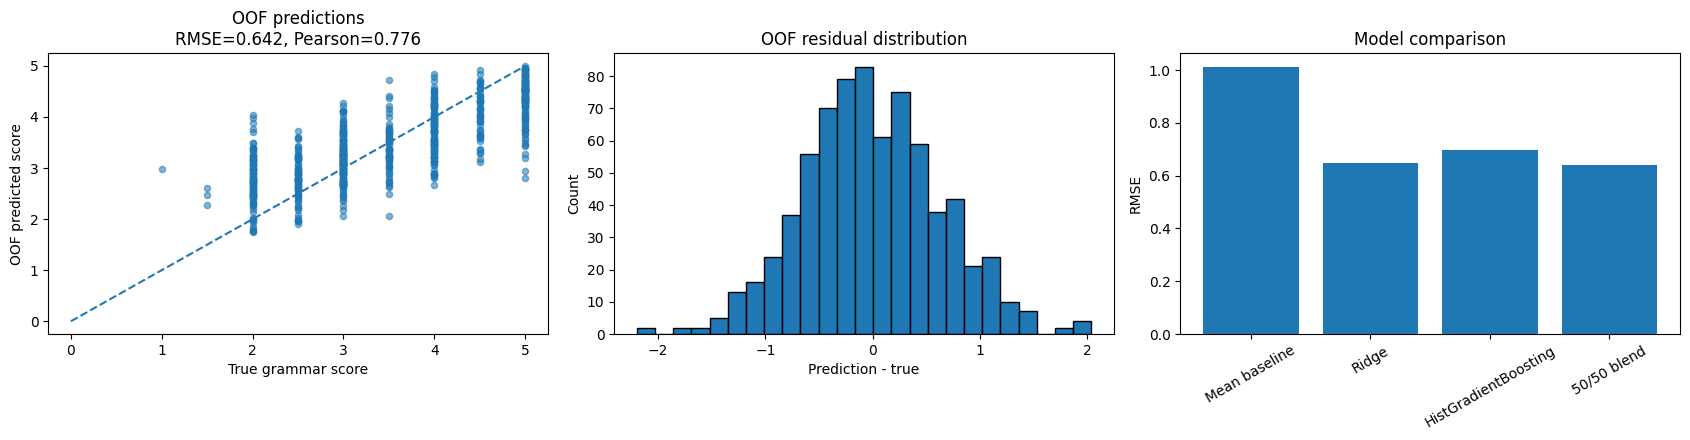

In [18]:

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 4.5)
)

# Prediction vs truth
axes[0].scatter(
    y_eval,
    blend_eval,
    alpha=0.55,
    s=20
)

axes[0].plot(
    [0, 5],
    [0, 5],
    "--"
)

axes[0].set_xlabel("True grammar score")
axes[0].set_ylabel("OOF predicted score")
axes[0].set_title(
    f"OOF predictions\n"
    f"RMSE={rmse(y_eval, blend_eval):.3f}, "
    f"Pearson={pearson(y_eval, blend_eval):.3f}"
)

# Residual distribution
residuals = blend_eval - y_eval

axes[1].hist(
    residuals,
    bins=25,
    edgecolor="black"
)

axes[1].set_xlabel("Prediction - true")
axes[1].set_ylabel("Count")
axes[1].set_title("OOF residual distribution")

# Model comparison
plot_results = results.copy()

axes[2].bar(
    plot_results["Model"],
    plot_results["RMSE_excluding_zeros"]
)

axes[2].set_ylabel("RMSE")
axes[2].set_title("Model comparison")
axes[2].tick_params(
    axis="x",
    rotation=30
)

plt.tight_layout()
plt.show()


## 14. Final model fit on all training data

In [19]:
final_text_train = [str(t).strip() or "speech" for t in text_train]
final_text_target = [str(t).strip() or "speech" for t in text_target]

full_word_vec = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=1,
    max_features=18000,
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32
)

full_char_vec = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=1,
    max_features=12000,
    sublinear_tf=True,
    dtype=np.float32
)

W_full = full_word_vec.fit_transform(
    final_text_train
)

W_target = full_word_vec.transform(
    final_text_target
)

C_full = full_char_vec.fit_transform(
    final_text_train
)

C_target = full_char_vec.transform(
    final_text_target
)

final_scaler = StandardScaler()

N_full = final_scaler.fit_transform(
    train_features[numeric_cols]
).astype(np.float32)

N_target = final_scaler.transform(
    target_features[numeric_cols]
).astype(np.float32
)

E_full = sparse.csr_matrix(
    emb_train
)

E_target = sparse.csr_matrix(
    emb_target
)

X_full_ridge = sparse.hstack(
    [
        W_full,
        C_full,
        sparse.csr_matrix(N_full),
        E_full
    ],
    format="csr"
)

X_target_ridge = sparse.hstack(
    [
        W_target,
        C_target,
        sparse.csr_matrix(N_target),
        E_target
    ],
    format="csr"
)

final_ridge = Ridge(
    alpha=20.0
)

final_ridge.fit(
    X_full_ridge,
    y
)

X_full_hgb = np.hstack(
    [
        train_features[numeric_cols].to_numpy(
            dtype=np.float32
        ),
        emb_train
    ]
)

X_target_hgb = np.hstack(
    [
        target_features[numeric_cols].to_numpy(
            dtype=np.float32
        ),
        emb_target
    ]
)

final_hgb = HistGradientBoostingRegressor(
    learning_rate=0.04,
    max_iter=250,
    max_leaf_nodes=15,
    min_samples_leaf=15,
    l2_regularization=2.0,
    random_state=SEED
)

final_hgb.fit(
    X_full_hgb,
    y
)

train_pred_ridge = final_ridge.predict(
    X_full_ridge
)

train_pred_hgb = final_hgb.predict(
    X_full_hgb
)

target_pred_ridge = final_ridge.predict(
    X_target_ridge
)

target_pred_hgb = final_hgb.predict(
    X_target_hgb
)

train_pred = np.clip(
    0.5 * train_pred_ridge
    + 0.5 * train_pred_hgb,
    0,
    5
)

target_pred = np.clip(
    0.5 * target_pred_ridge
    + 0.5 * target_pred_hgb,
    0,
    5
)

print("Final target predictions:", len(target_pred))
print(
    "Prediction range:",
    round(float(target_pred.min()), 4),
    "to",
    round(float(target_pred.max()), 4)
)


Final target predictions: 216
Prediction range: 1.1086 to 4.8964


## 15. Required training RMSE

The assignment explicitly requires the training RMSE.

It is reported here as an **in-sample** metric. The 5-fold OOF metrics above are the more appropriate estimate of generalization.

Primary reporting excludes zero-labelled samples, with all-label metrics shown secondarily for transparency.


In [20]:

training_nonzero_rmse = rmse(
    y_eval,
    train_pred[NONZERO_MASK]
)

training_nonzero_pearson = pearson(
    y_eval,
    train_pred[NONZERO_MASK]
)

oof_nonzero_rmse = rmse(
    y_eval,
    blend_eval
)

oof_nonzero_pearson = pearson(
    y_eval,
    blend_eval
)

training_all_rmse = rmse(
    y,
    train_pred
)

oof_all_rmse = rmse(
    y,
    oof_blend
)

print("====================================================")
print("PRIMARY METRICS — ZERO LABELS EXCLUDED")
print("====================================================")
print(
    "Required training RMSE (in-sample):",
    round(training_nonzero_rmse, 4)
)
print(
    "Training Pearson (in-sample):",
    round(training_nonzero_pearson, 4)
)
print(
    "5-fold OOF RMSE:",
    round(oof_nonzero_rmse, 4)
)
print(
    "5-fold OOF Pearson:",
    round(oof_nonzero_pearson, 4)
)

print("\n====================================================")
print("SECONDARY ALL-LABEL RMSE")
print("====================================================")
print(
    "Training RMSE:",
    round(training_all_rmse, 4)
)
print(
    "OOF RMSE:",
    round(oof_all_rmse, 4)
)

print("\nZero-labelled training samples:", int((y == 0).sum()))
print("Primary evaluation samples:", int(NONZERO_MASK.sum()))


PRIMARY METRICS — ZERO LABELS EXCLUDED
Required training RMSE (in-sample): 0.3083
Training Pearson (in-sample): 0.9614
5-fold OOF RMSE: 0.6422
5-fold OOF Pearson: 0.7758

SECONDARY ALL-LABEL RMSE
Training RMSE: 0.3066
OOF RMSE: 0.633

Zero-labelled training samples: 37
Primary evaluation samples: 732


## 16. Final submission gate

The final `submission.csv` is created directly from the prediction vector and the row order of `test.csv`. The notebook validates row count, unique IDs, prediction range, and column names before saving.

In [ ]:
submission = pd.DataFrame(
    {
        SUB_ID_COL: test_df[ID_COL].astype(str),
        SUB_PRED_COL: target_pred.astype(float),
    }
)

assert len(submission) == len(test_df), "Submission row count must equal test.csv row count."
assert submission[SUB_ID_COL].is_unique, "Submission IDs must be unique."
assert submission[SUB_PRED_COL].notna().all(), "Some test rows have missing predictions."
assert submission[SUB_PRED_COL].between(0, 5).all(), "All predictions must be inside [0, 5]."
assert submission[SUB_ID_COL].tolist() == test_df[ID_COL].tolist(), "Submission order does not match test.csv."
assert submission.columns.tolist() == [SUB_ID_COL, SUB_PRED_COL], "Unexpected submission columns."

submission_path = OUTPUT_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)

print("FINAL SUBMISSION CREATED")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Prediction range:", round(float(submission[SUB_PRED_COL].min()), 4), "to", round(float(submission[SUB_PRED_COL].max()), 4))
print("Saved:", submission_path)
display(submission.head(10))


FINAL SUBMISSION CREATED
Rows: 216
Columns: ['filename', 'label']
Prediction range: 1.1086 to 4.8964
Saved: /kaggle/working/submission.csv


,filename,label
0,audio_128.wav,3.081720
1,audio_156.wav,4.023281
2,audio_19.wav,3.825654
3,audio_108.wav,2.413442
4,audio_206.wav,2.603160
5,audio_161.wav,2.453122
6,audio_215.wav,3.028028
7,audio_213.wav,2.114832
8,audio_11.wav,3.325160
9,audio_155.wav,3.069224


# 17. Assignment report

## Approach

The target is a continuous human grammar rating for 45–60 second spoken-English recordings. The pipeline combines transcript-derived linguistic features, compact acoustic features, semantic embeddings, and sparse lexical features.

### Preprocessing

- WAV files are indexed by filename.
- Exact audio duplicates are checked using MD5.
- Audio is loaded at 16 kHz mono for acoustic analysis.
- Faster-Whisper performs English ASR with word timestamps and VAD.
- ASR and embedding outputs are cached with versioned cache names.
- Filename identity is never used as a predictive feature.

### Feature engineering

**Linguistic / grammar proxies**
- word count and lexical diversity
- sentence count and sentence-length statistics
- function-word and pronoun ratios
- clause-marker usage
- fillers and repetitions
- correction markers
- speech rate and articulation rate
- pause counts and pause durations
- ASR confidence indicators

**Acoustic**
- RMS energy
- zero-crossing rate
- spectral centroid
- spectral bandwidth
- spectral rolloff
- MFCC mean/std
- recording duration

**Semantic**
- 384-dimensional MiniLM transcript embeddings

**Sparse lexical**
- word TF-IDF n-grams
- character TF-IDF n-grams

### Models

Two complementary regressors are used:

1. Ridge regression on sparse lexical features, engineered numerical features, and MiniLM embeddings.
2. HistGradientBoosting on engineered numerical features and MiniLM embeddings.

A fixed 50/50 prediction blend is used.

### Validation

Five-fold grouped cross-validation is used. Audio hashes are used as groups so identical recordings cannot cross validation folds.

Primary RMSE and Pearson metrics exclude zero-labelled training samples because the supplied labels contain values outside the written 1–5 rubric.

### Required metric

The notebook explicitly reports the required in-sample training RMSE and Pearson correlation, with zero-labelled samples excluded from the primary report.

It also reports five-fold OOF RMSE and Pearson on the same primary evaluation population. OOF metrics are the preferred estimate of generalization.

### Submission

The final `submission.csv` is generated directly from `test.csv` using its ID order and the model's predicted grammar scores in the required target column.


In [25]:
summary = {
    "train_rows": len(train_df),
    "test_rows": len(test_df),
    "zero_label_rows": int((y == 0).sum()),
    "primary_eval_rows": int(NONZERO_MASK.sum()),
    "cross_split_exact_duplicate_hashes": int(
        len(cross_split_hashes)
    ),
    "same_content_common_filenames": int(
        len(same_content_common_names)
    ),
    "required_training_rmse_excluding_zeros":
        training_nonzero_rmse,
    "oof_rmse_excluding_zeros":
        oof_nonzero_rmse,
    "oof_pearson_excluding_zeros":
        oof_nonzero_pearson,
    "submission_rows": len(submission),
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Value"]
)

display(summary_df)

print("\nsubmission.csv was generated from test.csv")

,Metric,Value
0,train_rows,769.000000
1,test_rows,216.000000
2,zero_label_rows,37.000000
3,primary_eval_rows,732.000000
4,cross_split_exact_duplicate_hashes,0.000000
5,same_content_common_filenames,0.000000
6,required_training_rmse_excluding_zeros,0.308273
7,oof_rmse_excluding_zeros,0.642245
8,oof_pearson_excluding_zeros,0.775847
9,submission_rows,216.000000



submission.csv was generated from test.csv
